<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 4: Feature Selection I**

**Authors:** *Name 1, Name 2, Name 3, ...*

### Instructor review (2026-10-08)

This notebook (Group 4 – Feature Selection I) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- Bias–variance: OLS test-error formula linking #features to variance, simulation with theory curve
- F-regression: numerical check of F = r²(n−2)/(1−r²) and a selection-leakage demo (selector inside vs. outside CV)
- MIC: compact grid-based MIC implementation (minepy does not build), comparison |r| / F / MI / MIC on five relationships, numerical noise experiment, MIC vs. MI paragraph
- χ²: requirements, multiple testing, comparison with the full 2×2 contingency test
- Pearson: limitations (redundancy, missed non-linear feature)
- Takeaways (all three questions) and additional references

**Corrected**
- Bias–variance cell: garbled error formula replaced by the proper decomposition
- Pearson: description of the example (four features and one target, not four targets)
- MIC: heading levels; uniform (not just symmetric) distribution in the numerical example
- χ²: expected counts = total × class prior (code and text); sklearn's chi2 ≠ full 2×2 independence test

**Revised for clarity**
- Duplicate empty template headings (Pearson, F-regression) and an empty trailing cell removed
- MIC: normalization and the grid bound B(n) = n^0.6 explained; redundant 'Key Takeaways' merged into the final Takeaways

**Removed (beyond course scope)**
- (none)

**Open issue for the group:** the authors cell still contains the placeholder *Name 1, Name 2, ...* – please enter your names. The stored outputs of the original notebook were incomplete (`No module named sklearn`); this version was executed end-to-end.


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/04_Feature_Selection_1.png" width="1200"/>

## Introduction

**What is it about?**
*Feature selection* means choosing a subset of the available features that carries most of the relevant information about the target. *Univariate* (filter) methods score every feature individually against the target, independent of any learning algorithm: Pearson correlation measures linear dependence, the F-test (`f_regression`) tests the significance of a linear relationship, the Maximal Information Coefficient (MIC) and mutual information also detect non-linear dependencies, and the $\chi^2$ test assesses the dependence between non-negative/categorical features and a class label.

**Where is it used?**
Filter methods are a fast first step whenever there are many candidate features: gene-expression data with thousands of genes, text classification with large vocabularies, sensor data with many channels, or engineered feature sets from automated pipelines. In scikit-learn they are available via `SelectKBest`, `SelectPercentile`, `f_regression`, `mutual_info_regression` and `chi2`.

**Why is it important for Machine Learning?**
Irrelevant and redundant features increase variance and thus the risk of overfitting, slow down training and make models harder to interpret. In terms of the bias–variance tradeoff, removing uninformative features reduces variance at little cost in bias. Univariate methods are cheap and easy to explain, but they ignore interactions between features, which is an important limitation to understand.

## (i) Why feature selection helps (bias–variance tradeoff)



<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the error formula was garbled (duplicated plain text, not an expectation) and the link to feature selection was missing*

Feature selection is the process of choosing the most relevant features while removing variables that provide little useful information.
Understanding the bias–variance tradeoff explains *why* this helps. For a model $\hat f$ trained on a random training set, the expected test error at a point $x$ decomposes as

$$\mathbb{E}\big[(y-\hat f(x))^2\big] = \underbrace{\big(\mathbb{E}[\hat f(x)]-f(x)\big)^2}_{\text{Bias}^2} + \underbrace{\mathbb{E}\big[(\hat f(x)-\mathbb{E}[\hat f(x)])^2\big]}_{\text{Variance}} + \underbrace{\sigma^2}_{\text{irreducible error}}$$

where the expectation is taken over training sets (and the noise).

- **Bias²:** error caused by incorrect assumptions in the model (e.g. a relevant feature is missing).
- **Variance:** error caused by sensitivity to the particular training data (every extra parameter must be estimated from the same $n$ samples).
- **Irreducible error $\sigma^2$:** random noise in the data that cannot be eliminated.

A simple model may miss important patterns (high bias), while a very complex model may learn noise from training data (high variance). The aim is to balance both so the model performs well on new data.

**Link to feature selection.** For ordinary least squares with $p$ features and $n$ samples (Gaussian inputs, correct model) the expected test error is
$$\mathbb{E}[\text{MSE}_\text{test}] = \sigma^2_\text{eff}\Big(1+\frac{p}{n-p-1}\Big),\qquad \sigma^2_\text{eff}=\sigma^2+\textstyle\sum_{j\,\text{omitted}}\beta_j^2 .$$
Every *irrelevant* feature increases $p$ and therefore the variance term without reducing bias; dropping a *relevant* feature increases $\sigma^2_\text{eff}$ (bias). Good feature selection removes the first kind and keeps the second — this matters most when $p$ is not small compared with $n$.

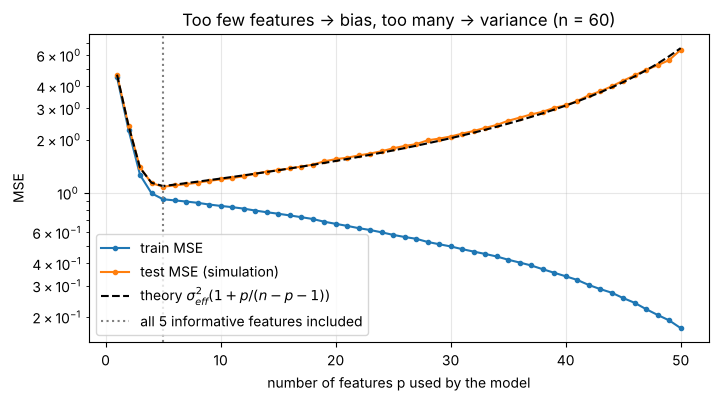

best p = 5, test MSE at p=5: 1.08, at p=50: 6.42


In [2]:
# [ADDED]
# Simulation: OLS on n = 60 samples; 5 informative features (decreasing |beta|), followed by 45 pure-noise features.
# We fit models using the first p features and average train / test MSE over many training sets.
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(0)
n, n_test, sigma, P, reps = 60, 1000, 1.0, 50, 100
beta = np.zeros(P); beta[:5] = [2, 1.5, 1, 0.5, 0.25]
ps = np.arange(1, P + 1)
mse_train, mse_test = np.zeros(P), np.zeros(P)
for _ in range(reps):
    Xb = rng.normal(size=(n, P));       yb = Xb @ beta + sigma * rng.normal(size=n)
    Xt = rng.normal(size=(n_test, P));  yt = Xt @ beta + sigma * rng.normal(size=n_test)
    for i, p in enumerate(ps):
        m = LinearRegression(fit_intercept=False).fit(Xb[:, :p], yb)
        mse_train[i] += np.mean((m.predict(Xb[:, :p]) - yb) ** 2) / reps
        mse_test[i]  += np.mean((m.predict(Xt[:, :p]) - yt) ** 2) / reps

sigma_eff2 = np.array([sigma**2 + np.sum(beta[p:] ** 2) for p in ps])   # omitted features act as noise (bias)
theory = sigma_eff2 * (1 + ps / (n - ps - 1))                              # + variance term p/(n-p-1)

plt.figure(figsize=(8, 4))
plt.plot(ps, mse_train, "o-", ms=3, label="train MSE")
plt.plot(ps, mse_test, "o-", ms=3, label="test MSE (simulation)")
plt.plot(ps, theory, "k--", label=r"theory $\sigma^2_{eff}(1+p/(n-p-1))$")
plt.axvline(5, color="grey", ls=":", label="all 5 informative features included")
plt.yscale("log"); plt.xlabel("number of features p used by the model"); plt.ylabel("MSE")
plt.title("Too few features → bias, too many → variance (n = 60)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"best p = {ps[np.argmin(mse_test)]}, test MSE at p=5: {mse_test[4]:.2f}, at p=50: {mse_test[-1]:.2f}")

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Reading the plot.** The training error decreases monotonically with every added feature, but the test error is U-shaped: left of $p=5$ relevant features are missing (bias), right of it each noise feature adds variance — with 50 features and 60 samples the test error is ~6× larger than with the 5 informative ones. The training error is therefore useless for choosing features; selection must be judged on held-out data.

## (ii) Univariate feature selection



### Pearson correlation

The Pearson correlation coefficient (r) measures how strongly two numeric variables are linearly related. The value ranges from −1 to +1.

$$r = \frac{\operatorname{cov}(X, Y)}{\sigma_X \, \sigma_Y}$$

It shows how much X and Y vary together, divided by how much each varies on its own. That normalization makes the result scale-free, so units don't matter.

**Interpretation**

- r ≈ +1: strong positive linear relationship (when X rises, Y rises)
- r ≈ −1: strong negative linear relationship (when X rises, Y falls)
- r ≈ 0: no linear relationship (but there may be a non-linear one)

**Example with mock data**

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the code builds four features and one target, not one x and four targets*

The cell below builds **four features and one target** $y = 3x_\text{strong} + 1.2x_\text{weak} + x_\text{curve}^2 + \varepsilon$: a strong and a weak linear feature, a pure-noise feature and a feature that enters only through its square. As a filter we rank the features by $|r|$ and keep the top $k$.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

rng = np.random.default_rng(0)
n = 200

x_strong = rng.normal(size=n)   # strong linear relationship
x_weak = rng.normal(size=n)     # weaker linear relationship
x_noise = rng.normal(size=n)    # no link to y
x_curve = rng.normal(size=n)    # linked to y only through its square

y = 3 * x_strong + 1.2 * x_weak + x_curve**2 + rng.normal(scale=0.5, size=n)

X = pd.DataFrame({
    "strong_linear": x_strong,
    "weak_linear": x_weak,
    "noise": x_noise,
    "nonlinear": x_curve,
})

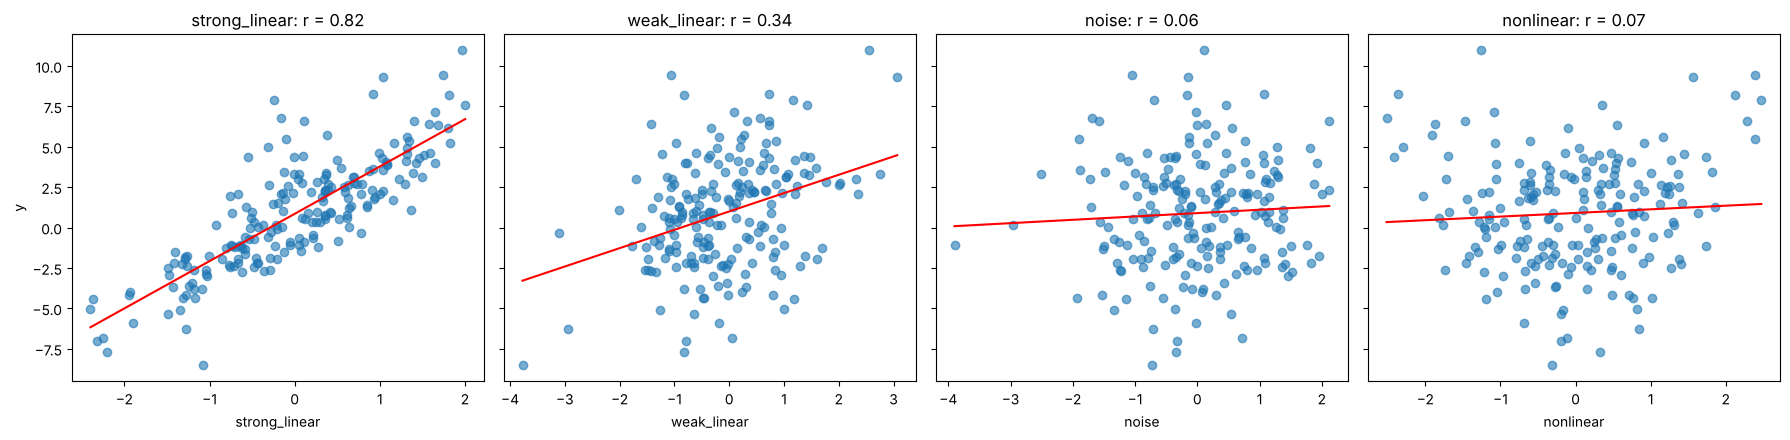

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)

for ax, col in zip(axes, X.columns):
    r = np.corrcoef(X[col], y)[0, 1]
    ax.scatter(X[col], y, alpha=0.6)

    m, b = np.polyfit(X[col], y, 1)          # regression line
    xs = np.linspace(X[col].min(), X[col].max(), 100)
    ax.plot(xs, m * xs + b, color="red")

    ax.set_title(f"{col}: r = {r:.2f}")
    ax.set_xlabel(col)

axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

In [5]:
rows = []
for col in X.columns:
    r_pandas = X[col].corr(pd.Series(y))
    r_numpy = np.corrcoef(X[col], y)[0, 1]
    r_scipy, p = pearsonr(X[col], y)

    # manual calculation straight from the formula
    xd, yd = X[col] - X[col].mean(), y - y.mean()
    r_manual = (xd * yd).sum() / np.sqrt((xd**2).sum() * (yd**2).sum())

    rows.append({"feature": col, "pandas": r_pandas, "numpy": r_numpy,
                 "scipy": r_scipy, "manual": r_manual, "p-value": p})

pearson_table = pd.DataFrame(rows).set_index("feature")
display(pearson_table.round(3))

,pandas,numpy,scipy,manual,p-value
feature,,,,,
strong_linear,0.824,0.824,0.824,0.824,0.000
weak_linear,0.341,0.341,0.341,0.341,0.000
noise,0.061,0.061,0.061,0.061,0.393
nonlinear,0.067,0.067,0.067,0.067,0.349


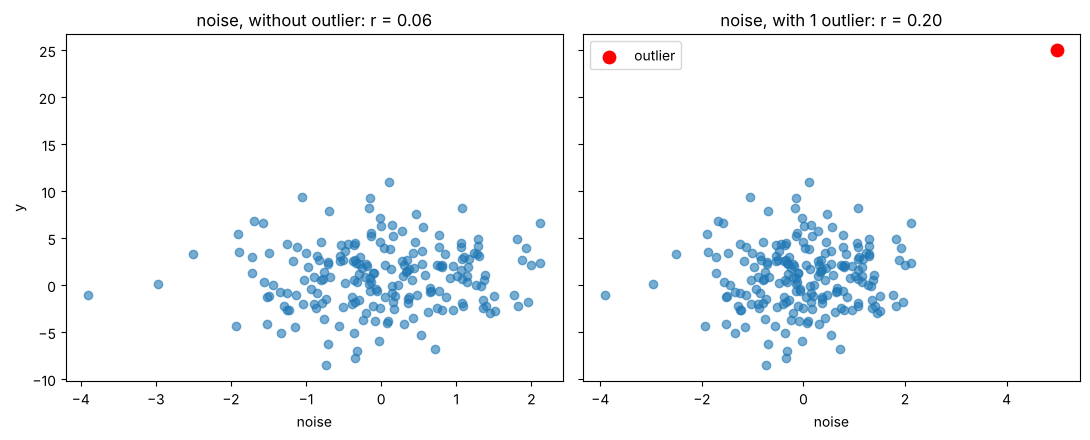

In [6]:
# Outliear demo

x_out = np.append(X["noise"], 5.0)    # add one extreme point
y_out = np.append(y, 25.0)

r_before = np.corrcoef(X["noise"], y)[0, 1]
r_after = np.corrcoef(x_out, y_out)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
axes[0].scatter(X["noise"], y, alpha=0.6)
axes[0].set_title(f"noise, without outlier: r = {r_before:.2f}")
axes[1].scatter(x_out[:-1], y_out[:-1], alpha=0.6)
axes[1].scatter(x_out[-1], y_out[-1], color="red", s=80, label="outlier")
axes[1].set_title(f"noise, with 1 outlier: r = {r_after:.2f}")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("noise")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()



**Important limitations**

- Only linear: a perfect parabola (y = x²) can have r ≈ 0.
- Sensitive to outliers: a single extreme point can distort r a lot.
- Assumes numeric, roughly continuous data.
<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>
- Redundancy is ignored: two (nearly) identical copies of a strong feature both get a high $|r|$ and are both selected.
- The `nonlinear` feature above has $r \approx 0$ although $y$ depends on it — it would be dropped by a correlation filter.


### F-regression

`f_regression` is a fast filter for a numeric target. It looks at **each feature on its own** and asks how strong the linear relationship between that feature and the target is.

For one feature it fits `y ≈ a + b·x` and compares two quantities: the spread of `y` that this linear relationship accounts for, and the spread left over. Their ratio is the **F-score**:

$$F = \frac{r^2\,(n-2)}{1-r^2}$$

Here `r` is the Pearson correlation between the feature and the target, and `n` is the number of rows. A large F-score means a strong linear relationship. The matching **p-value** says how surprising that relationship would be if the feature and the target were unrelated.

The figure shows the two distances for one point. The **red arrow** runs from the point to the mean of `y`. The **blue arrow** runs from the point to the fitted line, so it is the part the line does not account for. Over all points, the F-score compares the variation the line accounts for with the variation left in the blue arrows.

<img src="https://walshc.github.io/stats2/sse-sst.png" width="520"/>

*Source: [Colin Walsh, Statistics 2 for IBA](https://walshc.github.io/stats2/slr-r-squared.html).*

**Same relationship as Pearson correlation.** The F-score is the Pearson correlation `r` rewritten as a significance test. It covers the same linear relationship, and the feature order matches sorting by `|r|`. Two things differ:

- Pearson `r` keeps the direction (positive or negative) and stays on a fixed scale from −1 to 1.
- The F-score is always positive and grows with the number of rows. The same correlation therefore gets a smaller **p-value** when the sample is larger. That p-value is what F-regression adds.

Feature selection then keeps the top of that list, for example with `SelectKBest(f_regression, k=2)`. The example below prints `r` next to the F-score so the shared ranking is visible.

| Pros | Limitations |
|---|---|
| Very fast, also with thousands of features | Curved or threshold patterns score like noise |
| Easy to explain: a higher score is a stronger linear relationship with the target | Features are judged one by one, so interactions stay hidden |
| A score and a p-value, without training a model | Copies of the same signal all rank highly |
| Same ranking as the absolute Pearson correlation | Outliers can distort the score; compute it on the training rows only |

The cell below builds four features. Two have a linear relationship with `y`, one is pure noise, and one affects `y` only through its square. F-regression ranks the linear features first and treats the squared one like noise.



In [7]:
from sklearn.feature_selection import SelectKBest, f_regression

rng = np.random.default_rng(0)
n = 200

x_strong = rng.normal(size=n)   # strong linear relationship
x_weak = rng.normal(size=n)     # weaker linear relationship
x_noise = rng.normal(size=n)    # no link to y
x_curve = rng.normal(size=n)    # linked to y only through its square

y = 3 * x_strong + 1.2 * x_weak + x_curve**2 + rng.normal(scale=0.5, size=n)

X = pd.DataFrame({
    "strong_linear": x_strong,
    "weak_linear": x_weak,
    "noise": x_noise,
    "nonlinear": x_curve,
})

# Pearson r and the F-score rank features the same way. F-regression also returns a p-value.
pearson_r = X.apply(lambda col: np.corrcoef(col, y)[0, 1])
f_scores, p_values = f_regression(X, y)
scores = pd.DataFrame(
    {
        "Pearson r": pearson_r.round(2),
        "F-score": f_scores.round(1),
        "p-value": p_values,
    },
    index=X.columns,
).sort_values("F-score", ascending=False)
display(scores)

# Keep the two features with the highest F-scores.
selector = SelectKBest(score_func=f_regression, k=2)
selector.fit(X, y)
print("kept:", list(X.columns[selector.get_support()]))


,Pearson r,F-score,p-value
strong_linear,0.82,418.0,1.088499e-50
weak_linear,0.34,26.0,7.859069e-07
nonlinear,0.07,0.9,3.494402e-01
noise,0.06,0.7,3.930513e-01


kept: ['strong_linear', 'weak_linear']


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Check of the formula and the pitfall *selection leakage*.** The first lines verify $F = r^2(n-2)/(1-r^2)$ numerically. Then we use pure noise ($n=60$ samples, 2000 random features, random target): if `SelectKBest` is fitted on **all** data before cross-validation, the selected features have been chosen *because* they correlate with the test-fold targets by chance, and CV reports a clearly positive $R^2$. Fitted inside a `Pipeline`, selection is redone on each training fold and the honest $R^2 \le 0$ appears. The same holds for every filter score in this notebook (r, F, MI/MIC, χ²).

In [8]:
# [ADDED]
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold

r = pearson_r.values
print("F from r:", np.round(r**2 * (n - 2) / (1 - r**2), 1), "  f_regression:", np.round(f_scores, 1))

rng = np.random.default_rng(1)
X_noise, y_noise = rng.normal(size=(60, 2000)), rng.normal(size=60)
cv = KFold(5, shuffle=True, random_state=0)

X_sel = SelectKBest(f_regression, k=10).fit_transform(X_noise, y_noise)       # WRONG: selection sees all rows
r2_leaky = cross_val_score(LinearRegression(), X_sel, y_noise, cv=cv, scoring="r2").mean()
pipe = make_pipeline(SelectKBest(f_regression, k=10), LinearRegression())      # RIGHT: selection inside CV
r2_honest = cross_val_score(pipe, X_noise, y_noise, cv=cv, scoring="r2").mean()
print(f"CV R^2 with selection before CV (leakage): {r2_leaky:.2f}")
print(f"CV R^2 with selection inside the pipeline: {r2_honest:.2f}   (truth: y is pure noise)")

F from r: [418.   26.    0.7   0.9]   f_regression: [418.   26.    0.7   0.9]
CV R^2 with selection before CV (leakage): 0.51
CV R^2 with selection inside the pipeline: -0.15   (truth: y is pure noise)


<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *heading levels (#, ##) broke the notebook structure; distribution in the numerical example must be uniform; redundant 'Key Takeaways' moved to the final Takeaways; MIC vs MI added*


### Maximal Information Coefficient (MIC)

#### 1. What is MIC?

The **Maximal Information Coefficient (MIC)** is a statistical measure that quantifies the strength of dependence between two variables, regardless of whether their relationship is linear or nonlinear.

**Key properties:**
- MIC ranges from **0 to 1**.
- **MIC ≈ 0:** Little or no detected statistical dependence.
- **MIC ≈ 1:** Very strong statistical dependence.
- MIC detects linear, nonlinear, and other complex relationships.
- MIC does not indicate causality or the direction of a relationship.

**Main idea:** MIC measures how strongly an input feature $X$ is related to an output variable $Y$ without assuming a specific functional relationship.

---

#### 2. Example: A Nonlinear Relationship

Consider the following function:

$$
Y = X^2
$$

We generate input values between -3 and 3 and calculate the corresponding outputs.

| Input (X) | Output (Y = X²) |
|---|---|
| -3 | 9 |
| -2 | 4 |
| -1 | 1 |
| 0 | 0 |
| 1 | 1 |
| 2 | 4 |
| 3 | 9 |

**Observations:**
- The relationship is nonlinear (U-shaped).
- Each input value determines exactly one output value.
- There is a strong dependency between X and Y.
- MIC can detect this relationship.

**Question:** How can MIC identify this relationship?

---

#### 3. How Does MIC Work?

MIC searches for the grid partition that captures the strongest statistical dependence between X and Y.

**Step 1**: Divide the Data into a Grid

The scatter plot is divided into rectangular cells using a grid.

For example:
- A 2 × 2 grid creates 4 cells.
- A 3 × 2 grid creates 6 cells.
- A 4 × 4 grid creates 16 cells.

Each observation belongs to one cell based on its X and Y values.

**Step 2**: Calculate Mutual Information

Mutual Information (MI) measures how much information one variable provides about another.

$$
I(X;Y) =
\sum_x \sum_y
p(x,y)
\log_2
\left(
\frac{p(x,y)}{p(x)p(y)}
\right)
$$

Where:

- $p(x,y)$: Joint probability that X belongs to category x AND Y belongs to category y.
- $p(x)$: Probability that X belongs to category x.
- $p(y)$: Probability that Y belongs to category y.

If X and Y are independent:

$$
p(x,y) = p(x)p(y)
$$

Therefore:

$$
I(X;Y)=0
$$

**Step 3**: Normalize Mutual Information

Different grid sizes have different maximum possible Mutual Information values.

To make the values comparable, MIC uses normalization:

$$
\text{Normalized MI} =
\frac{I(X;Y)}
{\log_2(\min(n_x,n_y))}
$$

Where:
- $n_x$: Number of columns.
- $n_y$: Number of rows.
- $\min(n_x,n_y)$: Smaller number of grid divisions.

The normalized value ranges from 0 to 1, because $I(X;Y) \le \min(H(X),H(Y)) \le \log_2\min(n_x,n_y)$. Without this normalization finer grids would always win, since MI never decreases when a grid is refined.

**Step 4**: Evaluate Different Grids

MIC evaluates multiple grid configurations and grid boundaries.

For each grid:
1. Count the observations in each cell.
2. Calculate joint and marginal probabilities.
3. Compute Mutual Information.
4. Normalize the result.

**Step 5**: Select the Maximum

MIC selects the maximum normalized Mutual Information across the allowed grid partitions.

$$
\boxed{
MIC(X,Y)=
\max_{\substack{n_x,n_y\geq 2\\n_x n_y\leq B(n)}}
\frac{I^*(X,Y;n_x,n_y)}
{\log_2(\min(n_x,n_y))}
}
$$

Where:

- $I^*$: Maximum Mutual Information among grid partitions with the specified number of rows and columns.
- $B(n)$: Maximum grid complexity allowed for a dataset of size n (Reshef et al. use $B(n)=n^{0.6}$; without this bound every point could get its own cell and MIC would always be 1).
- $\max$: Selects the highest normalized value.

---

#### 4. Numerical Example: Mutual Information

Consider the relationship:

$$
Y=X^2
$$

We divide X into three categories:

- **Left:** X < -1.5
- **Middle:** -1.5 ≤ X < 1.5
- **Right:** X ≥ 1.5

And Y into two categories:

- **Low:** Y < 2.25
- **High:** Y ≥ 2.25

This produces a **3 × 2 grid**.

For a **uniformly** distributed input on $[-3,3]$ the theoretical joint probabilities are <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *'symmetric' is not enough – the probabilities 0.25/0.5/0.25 require a uniform X*:

| X Category | Y Low | Y High |
|---|---|---|
| Left | 0 | 0.25 |
| Middle | 0.50 | 0 |
| Right | 0 | 0.25 |

The marginal probabilities are:

$$
p(X) = (0.25, 0.50, 0.25)
$$

$$
p(Y) = (0.50, 0.50)
$$

We now calculate Mutual Information:

$$
I(X;Y)=
\sum_{x,y} p(x,y)
\log_2\left(\frac{p(x,y)}{p(x)p(y)}\right)
$$

Only cells with nonzero probabilities contribute:

$$
I(X;Y)=
0.25\log_2\left(\frac{0.25}{0.25\cdot0.5}\right)
+
0.5\log_2\left(\frac{0.5}{0.5\cdot0.5}\right)
+
0.25\log_2\left(\frac{0.25}{0.25\cdot0.5}\right)
$$

Simplifying:

$$
I(X;Y)=0.25+0.5+0.25
$$

$$
\boxed{I(X;Y)=1\text{ bit}}
$$

Now normalize:

$$
\text{Normalized MI}=
\frac{1}{\log_2(\min(3,2))}
$$

$$
=\frac{1}{\log_2(2)}=1
$$

**Interpretation:**

Knowing the X category allows us to determine the Y category perfectly.

This grid reaches the maximum possible normalized Mutual Information.

Therefore, MIC also reaches 1 when this grid partition is allowed.

For a finite sample, the exact values can differ slightly.

---

#### 5. MIC and Noise

In real-world datasets, relationships are usually not perfectly deterministic.

Consider:

$$
Y = X^2 + \varepsilon
$$

Where $\varepsilon$ represents random noise.

**Expected behaviour:**
- Without noise, MIC can detect a nearly perfect relationship.
- With noise, the statistical dependence generally becomes weaker.
- MIC may decrease as noise increases.

The exact MIC value depends on the data and the estimation procedure.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**MIC vs. mutual information (MI).** MI $I(X;Y)$ (e.g. `sklearn.feature_selection.mutual_info_regression`, a k-nearest-neighbour estimator in *nats*) is unbounded, depends on the marginal entropies and on the estimator. MIC is MI **normalized to [0,1] and maximized over grids**, which makes scores of different features comparable. Limitations: computationally expensive ($O(n^{1.2})$ grids per pair, approximated heuristically), positive small-sample bias (independent data give MIC > 0), and lower statistical power than e.g. distance correlation for noisy data (Simon & Tibshirani 2014).

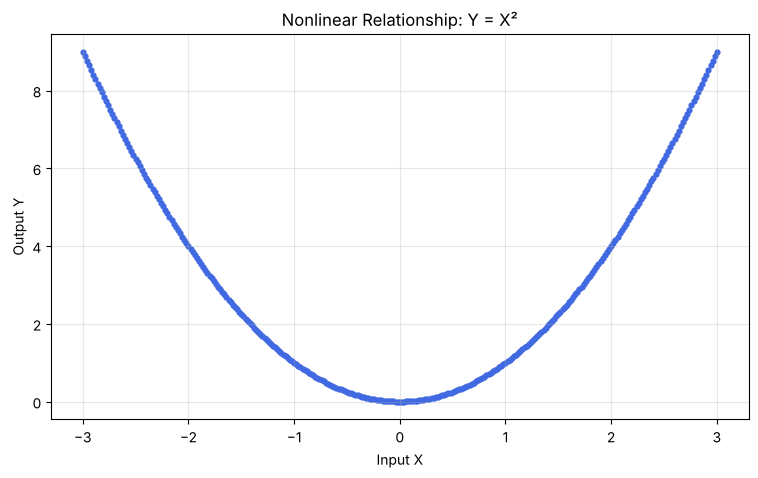

In [9]:
##Grafik 1: Nonlinear Relationship

import numpy as np
import matplotlib.pyplot as plt

# Generate data
x = np.linspace(-3, 3, 301)
y = x**2

plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=12, color="royalblue")

plt.title("Nonlinear Relationship: Y = X²")
plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.grid(alpha=0.3)
plt.show()


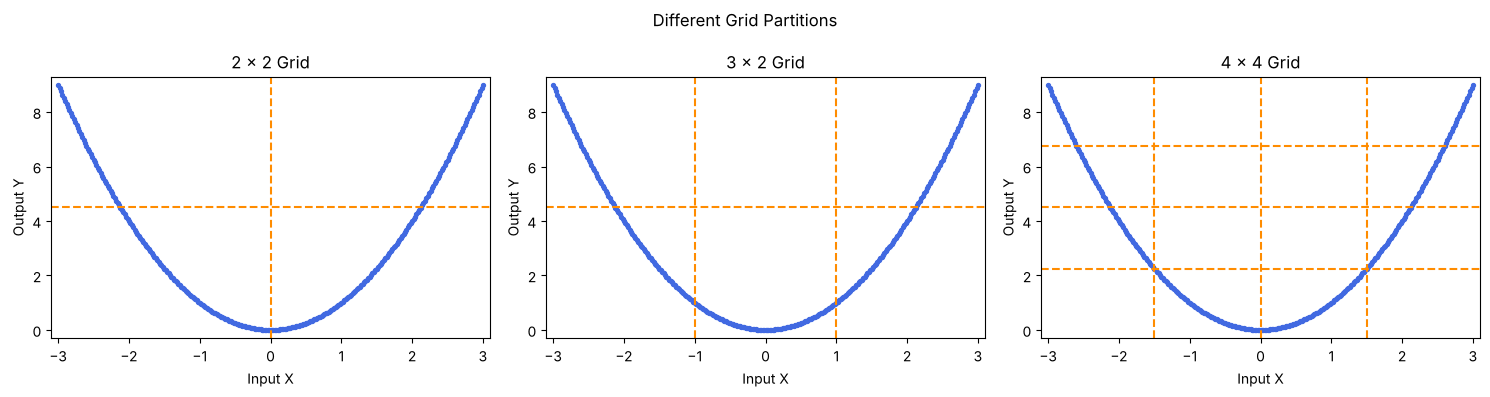

In [10]:
##Grafik 2: Different Grid Partitions

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

grid_sizes = [(2, 2), (3, 2), (4, 4)]

for ax, (nx, ny) in zip(axes, grid_sizes):
    ax.scatter(x, y, s=8, color="royalblue")

    x_edges = np.linspace(-3, 3, nx + 1)
    y_edges = np.linspace(0, 9, ny + 1)

    for edge in x_edges[1:-1]:
        ax.axvline(edge, color="darkorange", linestyle="--")

    for edge in y_edges[1:-1]:
        ax.axhline(edge, color="darkorange", linestyle="--")

    ax.set_title(f"{nx} × {ny} Grid")
    ax.set_xlabel("Input X")
    ax.set_ylabel("Output Y")
    ax.set_xlim(-3.1, 3.1)
    ax.set_ylim(-0.3, 9.3)

plt.suptitle("Different Grid Partitions")
plt.tight_layout()
plt.show()


Grid cell counts:
[[  0  75]
 [149   1]
 [  0  76]]

Joint probabilities:
[[0.    0.249]
 [0.495 0.003]
 [0.    0.252]]

Mutual Information: 0.9711 bits
Normalized MI: 0.9711


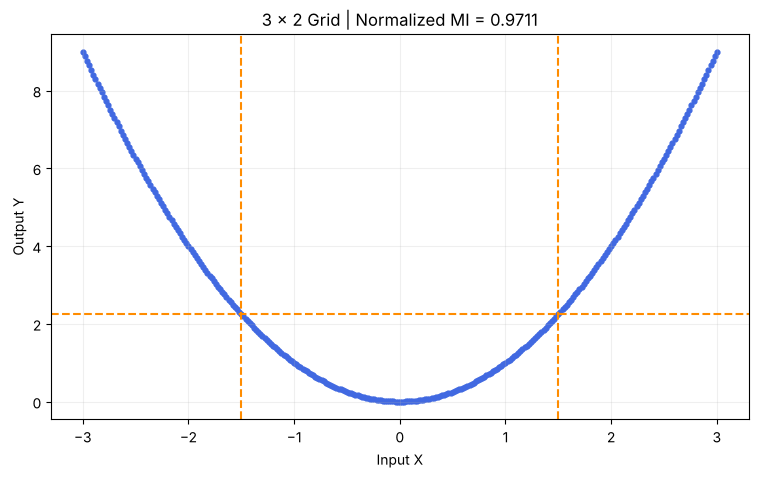

In [11]:
##Grafik 3: Mutual Information Calculation

import numpy as np
import matplotlib.pyplot as plt

# Generate data
x = np.linspace(-3, 3, 301)
y = x**2

# Define grid boundaries
x_edges = [-np.inf, -1.5, 1.5, np.inf]
y_edges = [-np.inf, 2.25, np.inf]

# Assign data points to categories
x_bins = np.digitize(x, x_edges[1:-1])
y_bins = np.digitize(y, y_edges[1:-1])

# Count observations in grid cells
counts = np.zeros((3, 2), dtype=int)

for xi, yi in zip(x_bins, y_bins):
    counts[xi, yi] += 1

# Compute probabilities
p_xy = counts / counts.sum()
p_x = p_xy.sum(axis=1)
p_y = p_xy.sum(axis=0)

# Calculate Mutual Information
mi = 0.0

for i in range(3):
    for j in range(2):
        if p_xy[i, j] > 0:
            mi += p_xy[i, j] * np.log2(
                p_xy[i, j] / (p_x[i] * p_y[j])
            )

# Normalize
normalized_mi = mi / np.log2(2)

print("Grid cell counts:")
print(counts)

print("\nJoint probabilities:")
print(np.round(p_xy, 3))

print(f"\nMutual Information: {mi:.4f} bits")
print(f"Normalized MI: {normalized_mi:.4f}")

# Visualize grid
plt.figure(figsize=(9, 5))
plt.scatter(x, y, s=12, color="royalblue")

plt.axvline(-1.5, color="darkorange", ls="--")
plt.axvline(1.5, color="darkorange", ls="--")
plt.axhline(2.25, color="darkorange", ls="--")

plt.title(f"3 × 2 Grid | Normalized MI = {normalized_mi:.4f}")
plt.xlabel("Input X")
plt.ylabel("Output Y")
plt.grid(alpha=0.2)
plt.show()


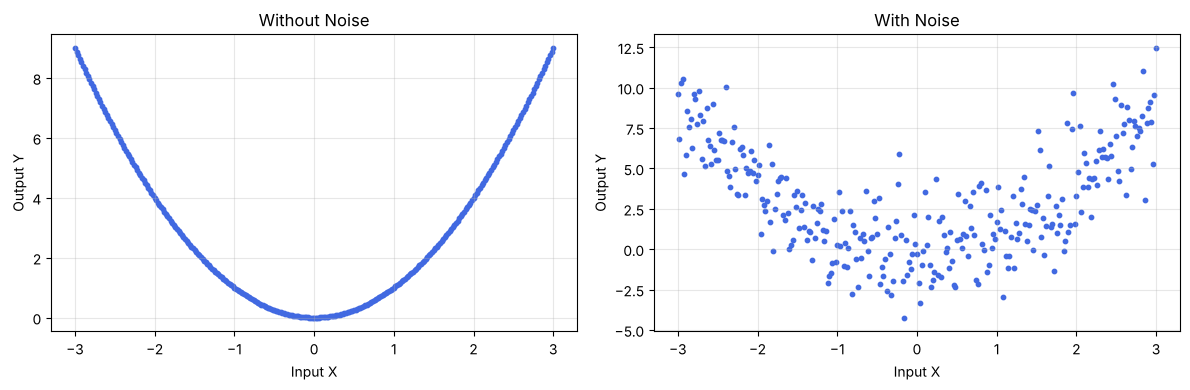

In [12]:
##Grafik 4: Effect of Noise

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

x = np.linspace(-3, 3, 301)
y_clean = x**2
y_noisy = x**2 + rng.normal(0, 2, len(x))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(x, y_clean, s=10, color="royalblue")
axes[0].set_title("Without Noise")

axes[1].scatter(x, y_noisy, s=10, color="royalblue")
axes[1].set_title("With Noise")

for ax in axes:
    ax.set_xlabel("Input X")
    ax.set_ylabel("Output Y")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Computing MIC.** The reference implementation `minepy` does not build on current Python versions, so the cell below implements a **compact grid-based approximation**: both axes are partitioned into equal-frequency (quantile) bins, the normalized MI is computed for every grid with $n_x n_y \le n^{0.6}$, and the maximum is returned. Because the bin boundaries are not optimized (the original algorithm searches them by dynamic programming), this is a slight *underestimate* of the true MIC. We compare it with |r|, the F-score and sklearn's MI estimator on one feature $x$ and different relationships, and repeat the noise experiment of Grafik 4 numerically.

In [13]:
# [ADDED]
from scipy.stats import rankdata
from sklearn.feature_selection import f_regression, mutual_info_regression

def mic_approx(x, y, alpha=0.6):
    """Simplified MIC: max over quantile grids (nx*ny <= n^alpha) of I(X;Y) / log2(min(nx, ny))."""
    n = len(x); B = max(int(n ** alpha), 4)
    rx = (rankdata(x, method="ordinal") - 1) / n          # ranks in [0, 1) -> equal-frequency bins
    ry = (rankdata(y, method="ordinal") - 1) / n
    best = 0.0
    for nx in range(2, B // 2 + 1):
        bx = (rx * nx).astype(int)
        for ny in range(2, B // nx + 1):
            by = (ry * ny).astype(int)
            pxy = np.zeros((nx, ny)); np.add.at(pxy, (bx, by), 1); pxy /= n
            pxpy = pxy.sum(1, keepdims=True) @ pxy.sum(0, keepdims=True)
            nz = pxy > 0
            mi = np.sum(pxy[nz] * np.log2(pxy[nz] / pxpy[nz]))
            best = max(best, mi / np.log2(min(nx, ny)))
    return best

rng = np.random.default_rng(0)
x = rng.uniform(-3, 3, 300)
eps = rng.normal(0, 0.3, 300)
targets = {"linear  y = x": x + eps, "parabola  y = x²": x**2 + eps, "sine  y = sin(2x)": np.sin(2 * x) + eps,
           "step  y = 1[x > 0]": (x > 0) + eps, "independent": rng.normal(size=300)}
rows = []
for name, t in targets.items():
    F, _ = f_regression(x.reshape(-1, 1), t)
    rows.append({"relationship": name, "|Pearson r|": abs(np.corrcoef(x, t)[0, 1]), "F-score": F[0],
                 "MI (nats, kNN)": mutual_info_regression(x.reshape(-1, 1), t, random_state=0)[0],
                 "MIC (approx.)": mic_approx(x, t)})
display(pd.DataFrame(rows).set_index("relationship").round(2))

# noise experiment of Grafik 4: MIC decreases with the noise level, Pearson r stays ~0 throughout
xg = np.linspace(-3, 3, 301)
for s in [0, 0.5, 1, 2, 4]:
    yg = xg**2 + np.random.default_rng(42).normal(0, s, len(xg))
    print(f"noise std {s}: MIC ≈ {mic_approx(xg, yg):.2f}, r = {np.corrcoef(xg, yg)[0, 1]:+.2f}")

,|Pearson r|,F-score,"MI (nats, kNN)",MIC (approx.)
relationship,,,,
linear y = x,0.99,11109.19,1.76,0.86
parabola y = x²,0.09,2.70,1.95,0.90
sine y = sin(2x),0.44,72.43,0.88,0.80
step y = 1[x > 0],0.74,371.01,0.48,0.73
independent,0.01,0.01,0.00,0.04


noise std 0: MIC ≈ 0.98, r = +0.00
noise std 0.5: MIC ≈ 0.86, r = +0.00
noise std 1: MIC ≈ 0.72, r = +0.00
noise std 2: MIC ≈ 0.48, r = +0.00
noise std 4: MIC ≈ 0.27, r = +0.00


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Interpretation.** |r| and F rank by *linear* trend only: the parabola looks like noise to them ($|r|\approx 0.1$), and the sine wave and the step are captured only through their linear component. MI and MIC detect all non-trivial dependences; MIC is on a fixed [0,1] scale, MI is not. The independent target still gets small positive MI/MIC values (estimation bias), so a threshold or a permutation test is needed. Note also that a *univariate* score measures the **marginal** dependence: in the 4-feature example above, the `nonlinear` feature has only a weak marginal relationship with $y$ because the strong linear term dominates the variance of $y$, so its marginal MIC is low as well — univariate scores cannot see that the feature is useful *in combination* with the others.

### $\chi^2$ test



**The idea in one sentence:** the $\chi^2$ test compares what we *actually counted* with what we *would expect if the feature had nothing to do with the target*. The bigger the gap, the more useful the feature.

$$\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i}$$

- $O$ = observed count, $E$ = expected count (the "fair share" if feature and target were independent)
- $H_0$: feature and target are independent → drop the feature
- $H_1$: feature and target are dependent → keep the feature

**Example: which words reveal spam?** 100 e-mails, 50 spam and 50 normal. Each word is a feature, "spam / normal" is the target.

- "free" appears in 50 e-mails. Fair share: 25 in each pile. Observed: 40 in spam, 10 in normal.
  $\chi^2 = \frac{(40-25)^2}{25} + \frac{(10-25)^2}{25} = 18$ → useful
- "hello" appears 25 / 25, exactly its fair share → $\chi^2 = 0$ → useless
- "meeting" appears 5 / 35 → $\chi^2 = 22.5$ → useful (it signals "not spam")

Everything above the critical value $3.84$ ($df = 1$, $\alpha = 0.05$) is unlikely to be chance.

$\chi^2$ is not the model. It is a filter *before* the model: score every feature, keep the best $k$, then train the classifier on those.

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the 'fair share' is only half/half because the classes are balanced, and sklearn's chi2 is not the full 2×2 independence test*

- **Expected counts in general:** $E_c = (\text{total count of the feature}) \times P(\text{class } c)$; "half / half" holds here only because there are 50 spam and 50 normal e-mails. That is also why the "fair share" of "meeting" (40 occurrences) is 20, not 25.
- **What `sklearn.feature_selection.chi2` computes:** it sums the feature values per class (only the "word present" cells) and compares them with the expected sums — the statistic computed by hand above. The *classical* $\chi^2$ test of independence on the full 2×2 table (present/absent × spam/normal) also counts the absent cells and gives a larger value (36 instead of 18 for "free"). The ranking is what matters for selection; the p-values are an approximation.
- **Requirements:** non-negative feature values (counts, frequencies, binary/one-hot indicators, TF-IDF) and a **categorical target**. Continuous features must be binned first; negative values raise an error.
- **Multiple testing:** with thousands of words, ~5 % of useless words exceed 3.84 by chance at $\alpha=0.05$; use the score only for ranking (`SelectKBest`) or correct the p-values (e.g. `SelectFdr`).

critical value (df=1, alpha=0.05) = 3.84


,in spam,in normal,expected each,chi2,p-value,keep?
word,,,,,,
free,40.0,10.0,25.0,18.0,0.000022,yes
hello,25.0,25.0,25.0,0.0,1.000000,no
meeting,5.0,35.0,20.0,22.5,0.000002,yes


sklearn chi2 scores: {'free': np.float64(18.0), 'hello': np.float64(0.0), 'meeting': np.float64(22.5)}
Selected features: ['free', 'meeting']


Accuracy with all 3 words: 0.75
Accuracy with the 2 selected words: 0.75


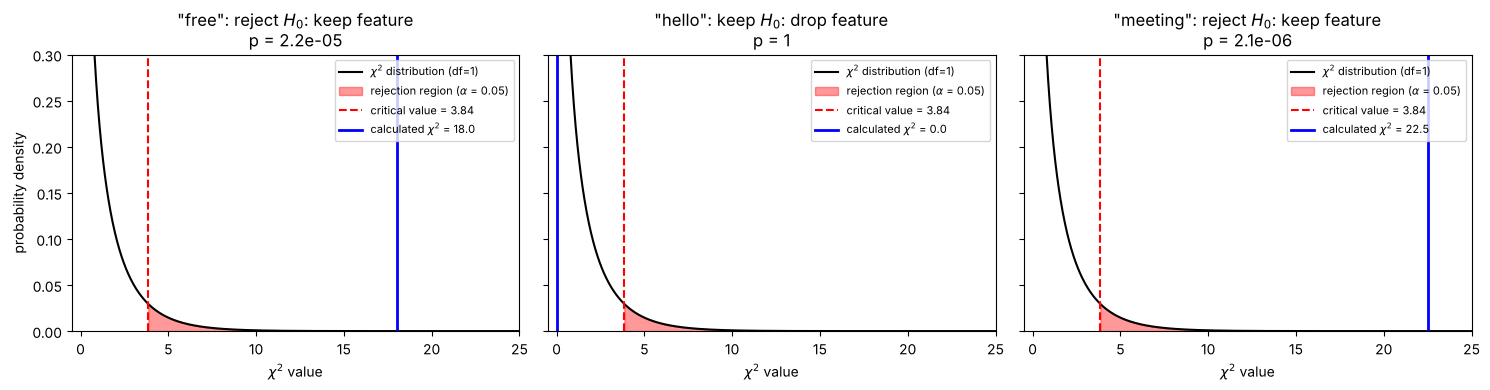

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

# 100 e-mails: first 50 are spam (1), last 50 are normal (0)
y = np.array([1] * 50 + [0] * 50)

def word(n_spam, n_normal):
    """1 = word appears in the e-mail, 0 = it does not."""
    return np.r_[np.ones(n_spam), np.zeros(50 - n_spam),
                 np.ones(n_normal), np.zeros(50 - n_normal)]

X = pd.DataFrame({"free": word(40, 10), "hello": word(25, 25), "meeting": word(5, 35)})

# ---------- Step 1: chi2 by hand (observed vs. expected) ----------
alpha, df = 0.05, 1
critical = stats.chi2.ppf(1 - alpha, df)

rows = []
for w in X.columns:
    observed = np.array([X[w][y == 1].sum(), X[w][y == 0].sum()])  # spam, normal
    prior = np.array([np.mean(y == 1), np.mean(y == 0)])
    expected = observed.sum() * prior   # [CORRECTED] E = total count × class prior (= half/half only for balanced classes)
    rows.append({"word": w, "in spam": observed[0], "in normal": observed[1],
                 "expected each": expected[0],
                 "chi2": ((observed - expected) ** 2 / expected).sum()})

table = pd.DataFrame(rows).set_index("word")
table["p-value"] = stats.chi2.sf(table["chi2"], df)
table["keep?"] = np.where(table["chi2"] > critical, "yes", "no")
print(f"critical value (df={df}, alpha={alpha}) = {critical:.2f}")
display(table)

# ---------- Step 2: the same with scikit-learn ----------
scores, pvalues = chi2(X, y)
print("sklearn chi2 scores:", dict(zip(X.columns, scores)))

selector = SelectKBest(chi2, k=2).fit(X, y)
print("Selected features:", list(X.columns[selector.get_support()]))

# ---------- Step 3: chi2 is the filter, the classifier comes afterwards ----------
all_words = cross_val_score(BernoulliNB(), X, y, cv=5).mean()
top_2     = cross_val_score(make_pipeline(SelectKBest(chi2, k=2), BernoulliNB()), X, y, cv=5).mean()
print(f"Accuracy with all 3 words: {all_words:.2f}")
print(f"Accuracy with the 2 selected words: {top_2:.2f}")

# ---------- Plot: chi2 distribution with rejection region, one panel per word ----------
x = np.linspace(0.01, 25, 1000)
pdf = stats.chi2.pdf(x, df)

fig, axes = plt.subplots(1, len(table), figsize=(15, 4), sharey=True)
for ax, (w, row) in zip(axes, table.iterrows()):
    ax.plot(x, pdf, color="black", label=f"$\\chi^2$ distribution (df={df})")
    ax.fill_between(x, pdf, where=(x >= critical), color="red", alpha=0.4,
                    label=f"rejection region ($\\alpha$ = {alpha})")
    ax.axvline(critical, color="red", linestyle="--", label=f"critical value = {critical:.2f}")
    ax.axvline(row["chi2"], color="blue", linewidth=2, label=f"calculated $\\chi^2$ = {row['chi2']:.1f}")
    decision = "reject $H_0$: keep feature" if row["chi2"] > critical else "keep $H_0$: drop feature"
    ax.set_title(f'"{w}": {decision}\np = {row["p-value"]:.2g}')
    ax.set_xlabel("$\\chi^2$ value")
    ax.set_xlim(-0.5, 25); ax.set_ylim(0, 0.3)
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("probability density")
plt.tight_layout(); plt.show()

In [15]:
# [ADDED]
# sklearn's chi2 (only 'word present' cells) vs. the classical chi2 test on the full 2x2 contingency table
for w in X.columns:
    table2x2 = pd.crosstab(X[w], y).values                      # rows: absent/present, cols: normal/spam
    chi2_full = stats.chi2_contingency(table2x2, correction=False)[0]
    print(f"{w:8s} sklearn chi2 = {chi2(X[[w]], y)[0][0]:5.1f}   full 2x2 test = {chi2_full:5.1f}")

free     sklearn chi2 =  18.0   full 2x2 test =  36.0
hello    sklearn chi2 =   0.0   full 2x2 test =   0.0
meeting  sklearn chi2 =  22.5   full 2x2 test =  37.5


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

## Takeaways

- **What should every ML practitioner remember?**
  - Irrelevant features add variance (OLS: test error $\propto 1 + p/(n-p-1)$) without reducing bias; selection pays off when $p$ is not small compared with $n$.
  - Univariate filters score each feature *alone* against the target: Pearson $r$ / F-regression → linear dependence only ($F = r^2(n-2)/(1-r^2)$, identical ranking to $|r|$); MI / MIC → any dependence (MIC normalized to [0,1]); $\chi^2$ → non-negative features vs. categorical target.
  - They are fast, model-agnostic and scale to thousands of features — a good first screening step.
- **What are common pitfalls?**
  - **Selection leakage:** fitting the selector on all data before CV gives optimistic scores (even $R^2>0$ on pure noise). Put `SelectKBest` into a `Pipeline`.
  - Univariate methods ignore **interactions** (XOR-type features score 0) and **redundancy** (duplicates are all kept).
  - Using r/F for non-linear relationships (parabola: $r\approx 0$); outliers distort $r$.
  - $\chi^2$ with negative or continuous features or a continuous target; expected counts must use the class priors.
  - Small p-values ≠ predictive value: with large $n$ tiny effects are significant, with many features many are significant by chance; choose $k$ by CV.
- **When does this technique really matter?**
  - High-dimensional data with few samples ($p \gtrsim n$): genomics, text (bag-of-words + $\chi^2$), many sensor channels, automatically generated features.
  - When training is expensive or interpretability is required, as a cheap pre-filter before wrapper/embedded methods (Lasso, RFE, tree importance — see Feature Selection II).

## References

*Cite the sources of all figures, diagrams and code snippets (URLs are sufficient).*
Bias-Variance:
1. https://www.geeksforgeeks.org/machine-learning/ml-bias-variance-trade-off/

MIC:
1. https://metricgate.com/docs/maximal-information-coefficient/

X^2:
1. https://www.quality-assurance-solutions.com/Chi-Square.html
2. https://medium.com/data-science/chi-square-test-for-feature-selection-in-machine-learning-206b1f0b8223
3. https://www.geeksforgeeks.org/data-science/chi-square-test-in-data-science-and-data-analytics/

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

General / F-regression / leakage:
1. scikit-learn User Guide, Univariate feature selection: https://scikit-learn.org/stable/modules/feature_selection.html#univariate-feature-selection
2. Hastie, Tibshirani, Friedman, *The Elements of Statistical Learning*, 2nd ed., Sec. 7.3 (bias–variance) and 7.10.2 (the wrong way to do CV): https://hastie.su.domains/ElemStatLearn/
3. Guyon & Elisseeff (2003), An Introduction to Variable and Feature Selection, JMLR 3: https://www.jmlr.org/papers/v3/guyon03a.html
4. Colin Walsh, Statistics 2 (figure SST/SSE): https://walshc.github.io/stats2/slr-r-squared.html

MIC / mutual information (additional):
1. Reshef et al. (2011), Detecting Novel Associations in Large Data Sets, Science 334: https://doi.org/10.1126/science.1205438
2. Simon & Tibshirani (2014), Comment on "Detecting Novel Associations in Large Data Sets": https://arxiv.org/abs/1401.7645
3. Kraskov, Stögbauer, Grassberger (2004), Estimating mutual information (kNN estimator used by sklearn): https://doi.org/10.1103/PhysRevE.69.066138